# ParaView output of the 2-D bump

Goal: write the 2-D bump to an HDF5 file, convert it to a VTK series (`pip install zoomy-prepost`) and open `vtk/bump_2d.pvd` in [ParaView](https://www.paraview.org) (*File → Open*, *Apply*, colour by `h`, play).

Prerequisite: [Quick start: a 2-D bump on NumPy and JAX](bump_2d.ipynb)

In [1]:
from pathlib import Path

import numpy as np
import jax
jax.config.update("jax_enable_x64", True)
import matplotlib.pyplot as plt
import meshio

import zoomy_core.model.initial_conditions as IC
from zoomy_core.mesh import LSQMesh
from zoomy_core.model.boundary_conditions import BoundaryConditions, FromModel
from zoomy_core.model.models import SME
from zoomy_core.model.models.closures import ManningFriction, Newtonian, StressFree
from zoomy_core.numerics import NumericalSystemModel, ReconstructionSpec
from zoomy_core.systemmodel.system_model import SystemModel
from zoomy_jax.symsolver.solver import SymbolicHyperbolicSolverJax
from zoomy_prepost import hdf5_to_vtk

In [2]:
walls = [FromModel(tag=t, definition="wall") for t in ("left", "right", "bottom", "top")]
model = SME(level=0, dimension=3, closures=[Newtonian(), ManningFriction(), StressFree()],
            boundary_conditions=BoundaryConditions(walls))
sm = SystemModel.from_model(model)
sm.initial_conditions = IC.UserFunction(function=lambda x: np.array(
    [0.0, 0.5 + 0.05 * np.exp(-((x[0] - 5.0) ** 2 + (x[1] - 5.0) ** 2) / 2.0), 0.0, 0.0]))
nsm = NumericalSystemModel.from_system_model(sm, reconstruction=ReconstructionSpec(order=1))
mesh = LSQMesh.create_2d(domain=(0, 10, 0, 10), nx=40, ny=40)

In [3]:
h5 = Path("bump_2d.h5").resolve()
solver = SymbolicHyperbolicSolverJax(time_end=2.5, cfl=0.9, mood=False, dt_write=0.25, output=str(h5))
Q, Qaux = solver.setup(mesh, nsm)
time, Q, Qaux = solver.run(Q, Qaux)

In [4]:
pvd = hdf5_to_vtk(h5, "vtk", "bump_2d", field_names=[str(v) for v in nsm.state])
frames = sorted(Path("vtk").glob("bump_2d_*.vtu"))
print(Path(pvd).relative_to(Path.cwd()), len(frames), "snapshots")

vtk/bump_2d.pvd 11 snapshots


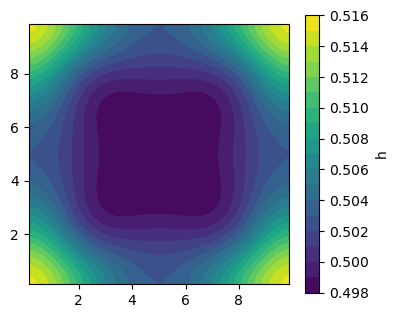

In [5]:
last = meshio.read(frames[-1])
xy = last.points[last.cells[0].data].mean(axis=1)[:, :2]
fig, ax = plt.subplots(figsize=(4.2, 3.6))
cs = ax.tricontourf(xy[:, 0], xy[:, 1], last.cell_data["h"][0], levels=20)
fig.colorbar(cs, ax=ax, label="h")
ax.set_aspect("equal")
plt.show()

In [6]:
assert len(frames) == 11
assert np.allclose(last.cell_data["h"][0], np.asarray(Q)[1, :mesh.n_inner_cells])